# Reservoir Facies Classification using Random Forest Ensembles
Project by **Neritya Kumar Singh** - 22410024, student at Indian Institute of Technology Roorkee, India

This notebook represents an independent student extension of a foundational machine learning workflow originally developed by Brendon Hall (Enthought). While the original demonstration utilized Support Vector Machines (SVMs) for classification, I have adapted and evolved this project to utilize a **Random Forest Classifier**. As an ensemble learning method, Random Forests are highly robust against multicollinearity and well-suited to handle the non-linear, imbalanced nature of subsurface petrophysical data.

### Geological Setting
The dataset utilized in this project is derived from the **Hugoton and Panoma Fields**, which constitute the largest natural gas fields in North America. Geologically, this is a highly heterogeneous **mixed carbonate-siliciclastic system**. Identifying distinct depositional facies in these strata is a critical step toward building accurate 3D reservoir models, mapping flow units, and characterizing reservoir quality.

### Datasets

This dataset originates from a consortium project and was featured in a class exercise at The University of Kansas on Neural Networks and Fuzzy Systems. 

* **Training Data:** The core dataset consists of wireline log data from **9 specific training wells**. These wells act as our "ground truth," as every depth interval has been explicitly labeled with one of 9 depositional facies types based on direct physical observation of core samples.
* **Validation Data:** The trained Random Forest model is ultimately applied to blind test wells (STUART and CRAWFORD) to predict facies where only wireline logs exist and core data is absent.

**Well Log Headers (Predictive Features):**
The algorithm maps the relationships between the following petrophysical measurements and the target facies:
* **GR:** Gamma Ray (primary indicator of shaliness and depositional energy)
* **ILD_log10:** Deep Induction Log (Resistivity)
* **DeltaPHI & PHIND:** Density-Neutron Porosity 
* **PE:** Photoelectric Factor (critical for distinguishing complex carbonate mineralogies, e.g., limestone vs. dolomite)
* **NM_M:** Non-marine / Marine depositional indicator
* **RELPOS:** Relative position within the stratigraphic sequence  

### Loading the Dataset and Libraries
Before training any predictive model, I must establish the geological baseline of our dataset. Wireline tools respond fundamentally to the physical and chemical properties of the rock matrix and its fluids:
* **Gamma Ray (GR):** Serves as our primary indicator of shaliness and depositional energy.
* **Photoelectric Factor (PE):** Critical for distinguishing complex carbonate lithologies (e.g., differentiating calcite-rich limestones from dolomites).
* **Porosity (DeltaPHI / PHIND):** Measures fluid-filled void space.

In [125]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [126]:
df = pd.read_csv('facies_vectors.csv')
df.head(5)

,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
0,3,A1 SH,SHRIMPLIN,2793.0,77.45,0.664,9.9,11.915,4.6,1,1.000
1,3,A1 SH,SHRIMPLIN,2793.5,78.26,0.661,14.2,12.565,4.1,1,0.979
2,3,A1 SH,SHRIMPLIN,2794.0,79.05,0.658,14.8,13.050,3.6,1,0.957
3,3,A1 SH,SHRIMPLIN,2794.5,86.10,0.655,13.9,13.115,3.5,1,0.936
4,3,A1 SH,SHRIMPLIN,2795.0,74.58,0.647,13.5,13.300,3.4,1,0.915


To optimize the Pandas dataframe for faster processing, I will convert the repetitive string data (like `Well Name` and `Formation`) into categorical data types. I am also extracting the unique well names to understand the spatial distribution of our training data across the reservoir.

In [127]:
df['Well Name'] = df['Well Name'].astype('category')
df['Formation'] = df['Formation'].astype('category')

unique_wells = df['Well Name'].unique()
print("Unique Wells in Dataset:")
print(unique_wells)

Unique Wells in Dataset:
['SHRIMPLIN', 'ALEXANDER D', 'SHANKLE', 'LUKE G U', 'KIMZEY A', 'CROSS H CATTLE', 'NOLAN', 'Recruit F9', 'NEWBY', 'CHURCHMAN BIBLE']
Categories (10, str): ['ALEXANDER D', 'CHURCHMAN BIBLE', 'CROSS H CATTLE', 'KIMZEY A', ..., 'NOLAN', 'Recruit F9', 'SHANKLE', 'SHRIMPLIN']


### Mapping Depositional Environments
The original dataset encodes facies as integers (1 through 9). To make our downstream visualizations and confusion matrices geologically readable, I am mapping these integers to their standard abbreviations (e.g., `SS` for Sandstone, `WS` for Wackestone). 

I am also generating a statistical summary (`describe()`) to inspect the value ranges of our logs and detect any missing data (`NaNs`).

In [128]:
# Defining the standard abbreviations for the 9 geological facies types
facies_colors = ['#F4D03F', '#F5B041','#DC7633','#6E2C00',
                 '#1B4F72','#2E86C1', '#AED6F1', '#A569BD', '#196F3D']

facies_labels = ['SS', 'CSiS', 'FSiS', 'SiSh', 'MS',
                 'WS', 'D','PS', 'BS']

# Mapping each label to a specific hex color so my downstream plots remain consistent
facies_color_map = {}
for ind, label in enumerate(facies_labels):
    facies_color_map[label] = facies_colors[ind]

# Helper function to convert the integer facies IDs into readable text abbreviations
def label_facies(row, labels):
    # Subtracting 1 to handle Python's 0-based indexing since the facies IDs start at 1
    return labels[row['Facies'] - 1]

# Applying the function to create a new text label column in my dataframe
df.loc[:, 'FaciesLabels'] = df.apply(lambda row: label_facies(row, facies_labels), axis=1)

# Checking the summary statistics to review the value ranges of my wireline logs
display(df.describe())

,Facies,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,4149.000000,4149.000000,4149.000000,4149.000000,4149.000000,4149.000000,3232.000000,4149.000000,4149.000000
mean,4.503254,2906.867438,64.933985,0.659566,4.402484,13.201066,3.725014,1.518438,0.521852
std,2.474324,133.300164,30.302530,0.252703,5.274947,7.132846,0.896152,0.499720,0.286644
min,1.000000,2573.500000,10.149000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.000000
25%,2.000000,2821.500000,44.730000,0.498000,1.600000,8.500000,3.100000,1.000000,0.277000
50%,4.000000,2932.500000,64.990000,0.639000,4.300000,12.020000,3.551500,2.000000,0.528000
75%,6.000000,3007.000000,79.438000,0.822000,7.500000,16.050000,4.300000,2.000000,0.769000
max,9.000000,3138.000000,361.150000,1.800000,19.312000,84.400000,8.094000,2.000000,1.000000


### Handling Missing Data

Older legacy wells in subsurface datasets frequently lack PE log runs. Decision tree-based machine learning algorithms cannot mathematically process rows containing missing values (`NaN`). Using boolean masking, I dynamically filter the dataset to retain only the depth intervals that have complete wireline suites.

In [129]:
PE_mask = df['PE'].notnull().values
df = df[PE_mask]
print(f"Total rows after removing missing PE values: {len(df)}")

Total rows after removing missing PE values: 3232


### Visualizing the Ground Truth (Core-Calibrated Logs)
Standard statistical summaries fail to capture the vertical, spatial reality of subsurface data. The function below generates a standard 6-track petrophysical log plot. By visualizing the core-calibrated facies track alongside the raw logs, you all can visually verify the expected log responses (e.g., low GR and high PE in wackestones/packstones, high GR in marine shales).

In [130]:
def make_facies_log_plot(logs, facies_colors):
    # Sorting the logs by depth to ensure the plot represents the true vertical stratigraphic sequence
    logs = logs.sort_values(by='Depth')
    
    # Creating a custom colormap using my previously defined facies colors
    cmap_facies = colors.ListedColormap(
            facies_colors[0:len(facies_colors)], 'indexed')
    
    # Defining the top and bottom of the well to set the y-axis limits
    ztop = logs.Depth.min(); zbot = logs.Depth.max()
    
    # Expanding the 1D facies array into a 2D block so it renders as a thick, continuous color track
    cluster = np.repeat(np.expand_dims(logs['Facies'].values, 1), 100, 1)
    
    # Initializing my figure with 6 individual tracks (subplots)
    f, ax = plt.subplots(nrows=1, ncols=6, figsize=(8, 12))
    
    # Plotting the standard petrophysical logs on tracks 1 through 5
    ax[0].plot(logs.GR, logs.Depth, '-g')
    ax[1].plot(logs.ILD_log10, logs.Depth, '-')
    ax[2].plot(logs.DeltaPHI, logs.Depth, '-', color='0.5')
    ax[3].plot(logs.PHIND, logs.Depth, '-', color='r')
    ax[4].plot(logs.PE, logs.Depth, '-', color='black')
    
    # Plotting the geological facies interpretation on the final track
    im = ax[5].imshow(cluster, interpolation='none', aspect='auto',
                    cmap=cmap_facies, vmin=1, vmax=9)
    
    # Setting up a custom colorbar legend
    divider = make_axes_locatable(ax[5])
    cax = divider.append_axes("right", size="20%", pad=0.05)
    cbar = plt.colorbar(im, cax=cax)
    
    # Aligning the facies labels exactly in the center of each color block
    # Using np.linspace(1.5, 8.5, 9) because facies are 1-9
    cbar.set_ticks(np.linspace(1.5, 8.5, 9))
    cbar.set_ticklabels(['SS', 'CSiS', 'FSiS', 'SiSh', 'MS', 'WS', 'D', 'PS', 'BS'])
    cbar.ax.tick_params(size=0) # Removing tick marks for a cleaner look
    
    # Formatting the axes
    for i in range(len(ax)-1):
        ax[i].set_ylim(ztop, zbot)
        ax[i].invert_yaxis()
        ax[i].grid(True, linestyle='--', alpha=0.7) 
        ax[i].locator_params(axis='x', nbins=3)
        ax[i].tick_params(axis='both', labelsize=8) 
        
    ax[5].tick_params(axis='both', labelsize=8) 

    # Adding labels and calculating dynamic limits for the x-axes
    ax[0].set_xlabel("GR")
    ax[0].set_xlim(logs.GR.min(), logs.GR.max())
    ax[1].set_xlabel("ILD_log10")
    ax[1].set_xlim(logs.ILD_log10.min(), logs.ILD_log10.max())
    ax[2].set_xlabel("DeltaPHI")
    ax[2].set_xlim(logs.DeltaPHI.min(), logs.DeltaPHI.max())
    ax[3].set_xlabel("PHIND")
    ax[3].set_xlim(logs.PHIND.min(), logs.PHIND.max())
    ax[4].set_xlabel("PE")
    ax[4].set_xlim(logs.PE.min(), logs.PE.max())
    ax[5].set_xlabel('Facies')
    
    # Hiding depth ticks on inner tracks to reduce clutter
    ax[1].set_yticklabels([]); ax[2].set_yticklabels([]); ax[3].set_yticklabels([])
    ax[4].set_yticklabels([]); ax[5].set_yticklabels([])
    ax[5].set_xticklabels([])
    
    f.suptitle('Well: %s' % logs.iloc[0]['Well Name'], fontsize=14, y=0.94)

Visualizing well: CHURCHMAN BIBLE


Visualizing well: LUKE G U


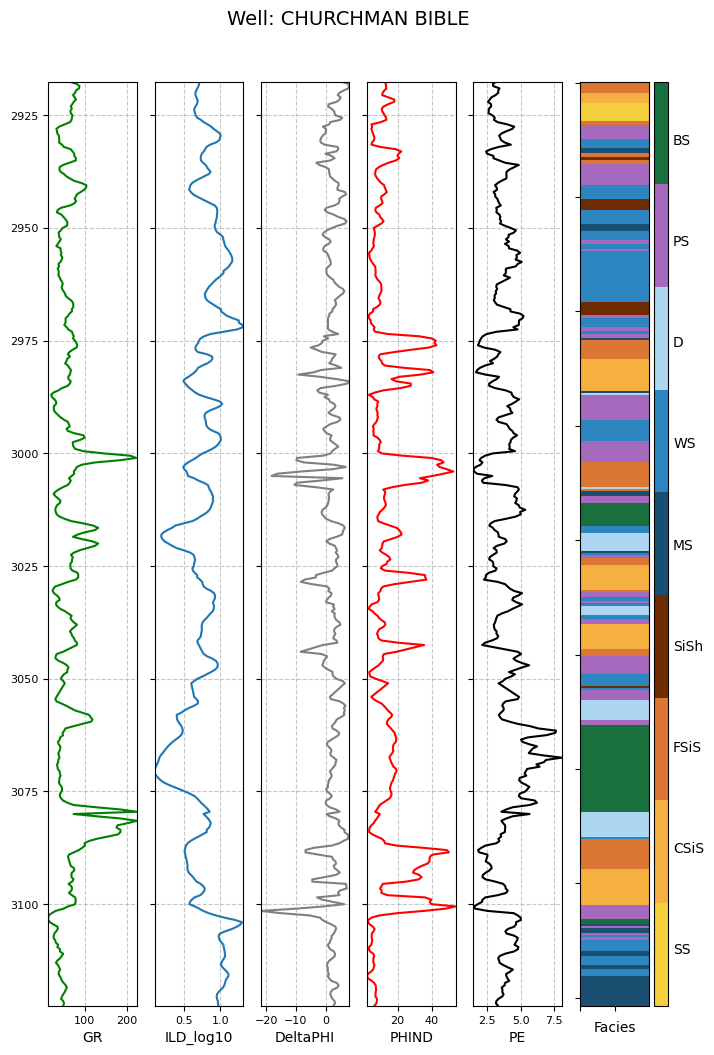

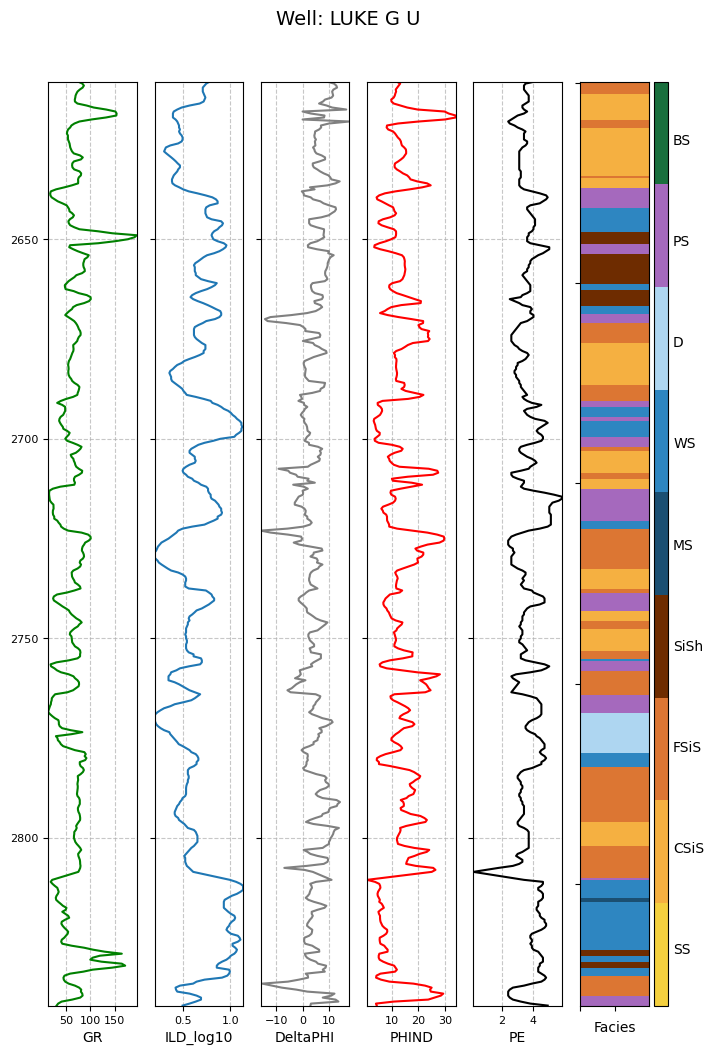

In [131]:
# Plotting the CHURCHMAN BIBLE well
print("Visualizing well: CHURCHMAN BIBLE")
make_facies_log_plot(
    df[df['Well Name'] == 'CHURCHMAN BIBLE'],
    facies_colors
)

# Plotting the LUKE G U well
print("Visualizing well: LUKE G U")
make_facies_log_plot(
    df[df['Well Name'] == 'LUKE G U'],
    facies_colors
)

### Assessing Geological Class Imbalance
Subsurface datasets are rarely perfectly balanced. In the Hugoton field, background depositional environments like Marine Siltstones/Shales (`SiSh`) and low-energy Wackestones (`WS`) dominate the stratigraphic column, while high-energy reservoir rocks like Sandstones (`SS`) or secondary Dolomites (`D`) are stratigraphically thinner and less frequent. 

Identifying this severe class imbalance is critical; if left unaddressed, the machine learning algorithm will naturally bias its predictions toward the dominant background shales and miss the critical, thin reservoir zones.

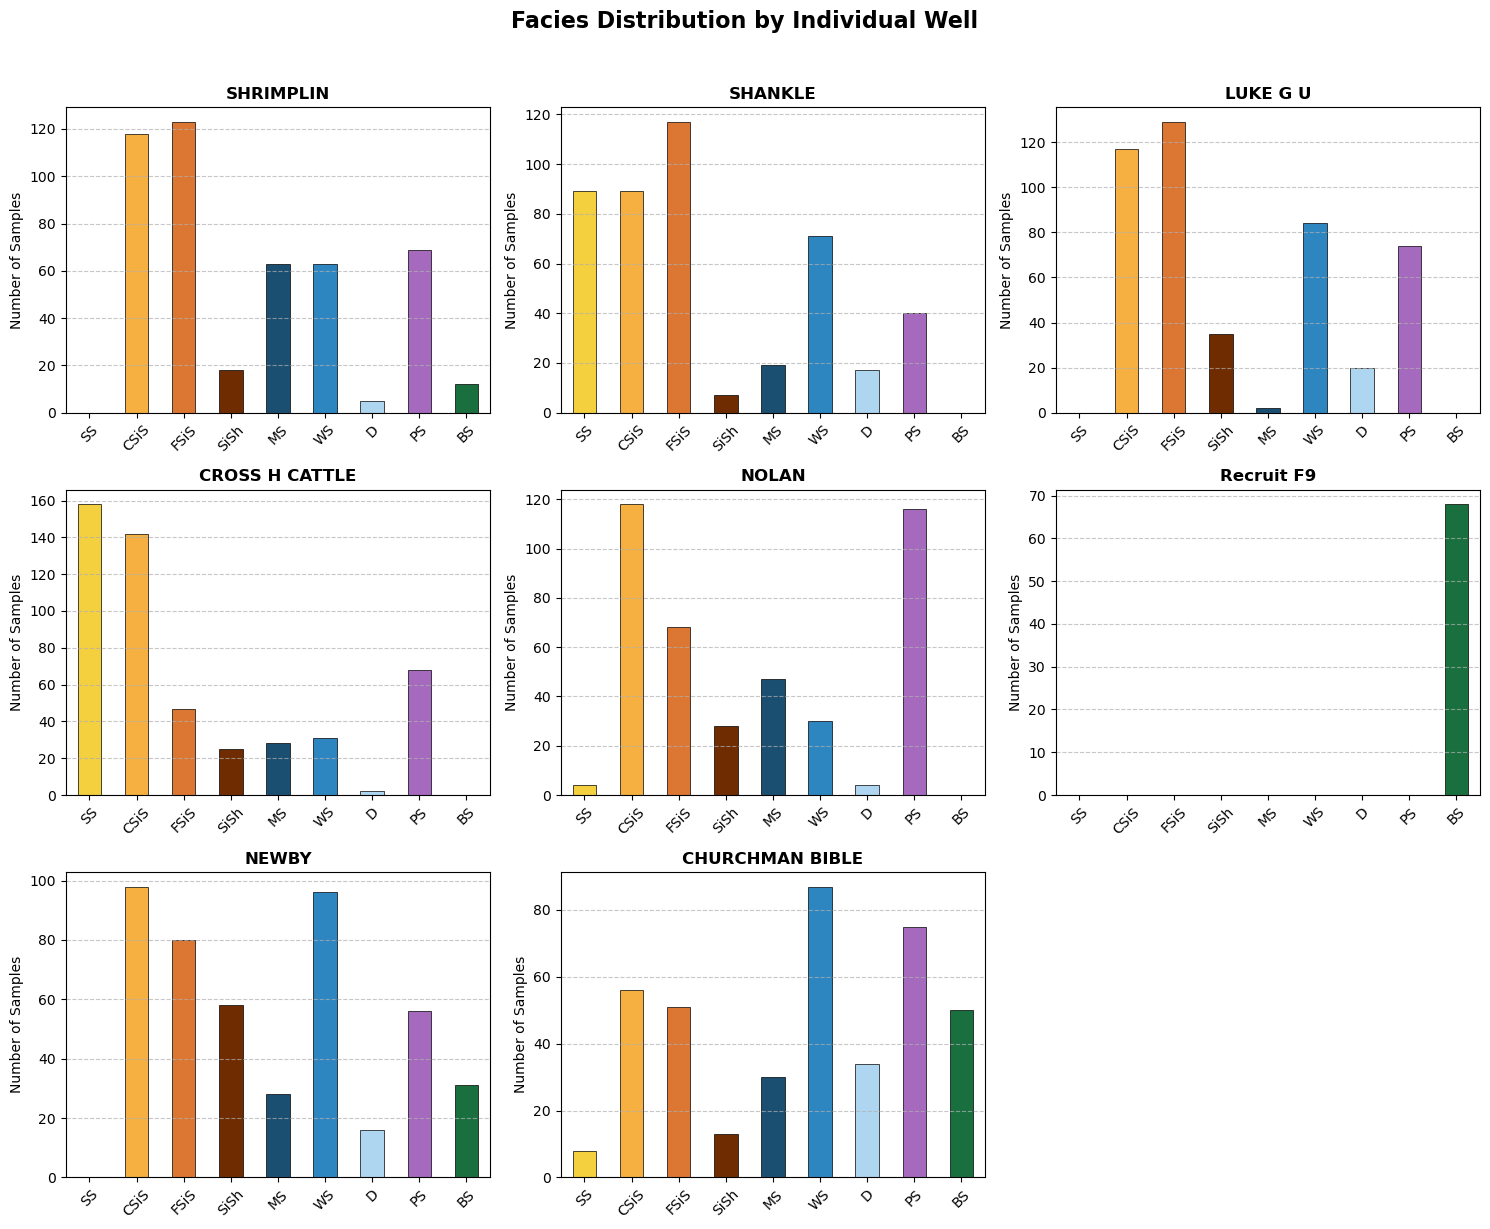

In [132]:
import math

# Extracting the unique well names to understand how many individual plots I need to generate
wells = df['Well Name'].unique()
num_wells = len(wells)

# Calculating the grid dimensions to fit all my well plots cleanly (using 3 columns)
cols = 3
rows = math.ceil(num_wells / cols)

# Setting up the master figure and flattening the axes array so I can loop through it easily
fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(15, 4 * rows))
axes = axes.flatten() 

# Iterating through my list of wells to build a separate bar chart for each one
for i, well in enumerate(wells):
    ax = axes[i]
    
    # Isolating the log data for the current well
    well_data = df[df['Well Name'] == well]
    
    # Counting the occurrences of each facies type and sorting them sequentially
    counts = well_data['Facies'].value_counts().sort_index()
    
    # Reindexing is critical here: it ensures all 9 facies appear on the x-axis, 
    # so my charts align perfectly even if a well is missing a specific rock type
    counts = counts.reindex(range(1, 10), fill_value=0)
    counts.index = facies_labels
    
    # Generating the bar chart using my consistent facies color map
    counts.plot(kind='bar', color=facies_colors, ax=ax, edgecolor='black', linewidth=0.5)
    
    # Applying standard formatting to make my charts readable
    ax.set_title(well, fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Samples')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=45)

# Cleaning up the grid by deleting any leftover empty subplots at the end
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Adding my final title and rendering the complete multi-well dashboard
fig.suptitle('Facies Distribution by Individual Well', fontsize=16, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

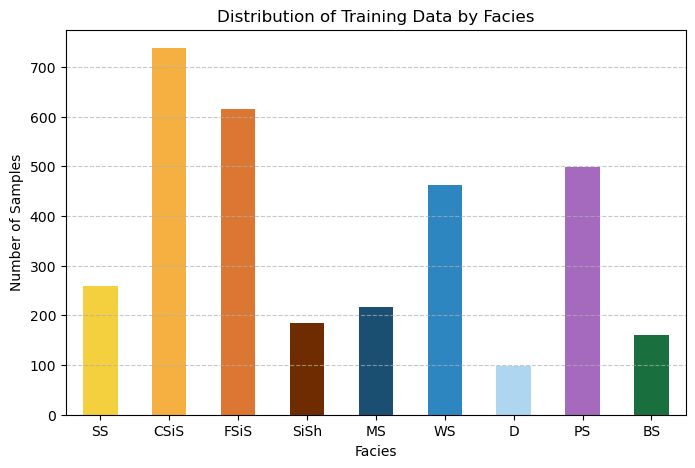

Exact Sample Counts:
SS      259
CSiS    738
FSiS    615
SiSh    184
MS      217
WS      462
D        98
PS      498
BS      161
Name: count, dtype: int64


In [133]:
# Counting the number of samples for each facies type and sorting them by their integer ID to check for class imbalance
facies_counts = df['Facies'].value_counts().sort_index()

# Replacing the integer indices with my readable string abbreviations for a cleaner x-axis
facies_counts.index = facies_labels

# Generating the bar chart using my established color palette
facies_counts.plot(
    kind='bar', 
    color=facies_colors, 
    title='Distribution of Training Data by Facies',
    figsize=(8, 5) # Expanding the figure size slightly to prevent the labels from overlapping
)

# Applying standard formatting and rendering the plot
plt.xlabel('Facies')
plt.ylabel('Number of Samples')
plt.grid(axis='y', linestyle='--', alpha=0.7) # Adding faint horizontal grid lines to make it easier to read the exact values
plt.xticks(rotation=0) # Keeping the x-axis labels upright for better readability
plt.show()

# Printing the exact sample counts below the chart to have the hard numbers alongside the visual
print("Exact Sample Counts:")
print(facies_counts)

## Phase 2: Feature Engineering & Preprocessing
To prepare the dataset for the Random Forest algorithm, I am isolating the predictive numerical logs (Features, `X`) from the target variable (Facies, `y`). 

**Algorithmic Conditioning:**
1. **Feature Dropping:** Non-predictive metadata (`Well Name`, `Formation`, `Depth`) are stripped. If left in, the algorithm might memorize the geographic location of the well rather than learning the actual physics of the rock.
2. **Scaling:** While Random Forests are theoretically scale-invariant, I am applying a `StandardScaler` to normalize the log distributions, preventing logs with naturally high values (like GR) from mathematically overpowering logs with small values (like PE).
3. **Cross-Validation Split:** I partitioned the data into an 80% training matrix and a 20% blind testing matrix to evaluate the model's true predictive power.

In [134]:
correct_facies_labels = df['Facies'].values

feature_vectors = df.drop(['Formation', 'Well Name', 'Depth','Facies','FaciesLabels'], axis=1)
feature_vectors.describe()

,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000
mean,66.135769,0.642719,3.559642,13.483213,3.725014,1.498453,0.520287
std,30.854826,0.241845,5.228948,7.698980,0.896152,0.500075,0.286792
min,13.250000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.010000
25%,46.918750,0.492750,1.163750,8.346750,3.100000,1.000000,0.273000
50%,65.721500,0.624437,3.500000,12.150000,3.551500,1.000000,0.526000
75%,79.626250,0.812735,6.432500,16.453750,4.300000,2.000000,0.767250
max,361.150000,1.480000,18.600000,84.400000,8.094000,2.000000,1.000000


In [135]:
from sklearn import preprocessing

scaler = preprocessing.StandardScaler().fit(feature_vectors)
scaled_features = scaler.transform(feature_vectors)

In [136]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
        scaled_features, correct_facies_labels, test_size=0.2, random_state=42)

print(f"\nTraining features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")


Training features shape: (2585, 7)
Testing features shape: (647, 7)


## Phase 3: Model Architecture & Training
In this phase, I am deploying a **Random Forest Classifier**, an ensemble learning method that constructs a multitude of decision trees during training. 

Unlike linear models, Random Forests are highly robust against multicollinearity and excel at partitioning the highly non-linear, overlapping log signatures typical of mixed carbonate-siliciclastic systems. 

**Handling the Imbalance:**
I implemented the `class_weight='balanced'` parameter. This mathematically penalizes the algorithm more heavily for misclassifying rare reservoir rocks (like Sandstones) than for misclassifying dominant background shales, forcing the model to respect the minority classes.

**Evaluation Metrics:**
Because depositional facies naturally grade into one another (e.g., a muddy wackestone blending into a packstone), I am evaluating both the "Exact" accuracy and "Adjacent" accuracy.

In [137]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# 1. Initialize the Random Forest
# I am using class_weight='balanced' to handle the massive imbalance.
# n_estimators=100
clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# 2. Train the model
clf.fit(X_train, y_train)

# 3. Predict on the unseen test data
predicted_labels = clf.predict(X_test)

In [138]:
import numpy as np

conf = confusion_matrix(y_test, predicted_labels)
def accuracy(conf):
    total_correct = 0.
    nb_classes = conf.shape[0]
    for i in np.arange(0,nb_classes):
        total_correct += conf[i][i]
    acc = total_correct/sum(sum(conf))
    return acc

# Adjacent facies definition and accuracy
adjacent_facies = np.array([[1], [0,2], [1], [4], [3,5], [4,6,7], [5,7], [5,6,8], [6,7]], dtype=object)

def accuracy_adjacent(conf, adjacent_facies):
    nb_classes = conf.shape[0]
    total_correct = 0.
    for i in np.arange(0,nb_classes):
        total_correct += conf[i][i]
        for j in adjacent_facies[i]:
            total_correct += conf[i][j]
    return total_correct / sum(sum(conf))


print('Random Forest Facies classification accuracy = %f' % accuracy(conf))
print('Random Forest Adjacent facies classification accuracy = %f' % accuracy_adjacent(conf, adjacent_facies))

Random Forest Facies classification accuracy = 0.732612
Random Forest Adjacent facies classification accuracy = 0.930448


## Phase 4: Blind Validation & Geological Interpretation
The ultimate test of a petrophysical machine learning model is its application to un-cored, unseen wells. Here,  I am deploying our trained Random Forest onto two blind validation wells (`STUART` and `CRAWFORD`).

**Evaluating the Output:**
Because we lack absolute core-derived ground truth for these specific wells, the evaluation shifts from mathematical percentage accuracy to geological validity. We analyze the AI-predicted facies tracks for:
* **Walther's Law Compliance:** Do the vertical successions represent realistic lateral shifts in depositional environments?
* **Blockiness:** Does the model predict contiguous, geologically sensible bed thicknesses, or is it overly sensitive to high-frequency wireline noise?

Clean, thick successions of predicted reservoir facies confirm that the algorithm has successfully mapped the wireline physics to the geology, providing a highly automated, mathematically rigorous foundation for subsurface correlation.

In [139]:
well_data = pd.read_csv('validation_data_nofacies.csv')
well_data['Well Name'] = well_data['Well Name'].astype('category')
well_data['Formation'] = well_data['Formation'].astype('category')
well_features = well_data.drop(['Formation', 'Well Name', 'Depth'], axis=1)

In [140]:
X_unknown = scaler.transform(well_features)

In [141]:
y_unknown = clf.predict(X_unknown)
well_data['Facies'] = y_unknown

#Unique Wells
print("Wells successfully classified:", well_data['Well Name'].unique())

Wells successfully classified: ['STUART', 'CRAWFORD']
Categories (2, str): ['CRAWFORD', 'STUART']



--- Visualizing Predicted Facies for STUART ---


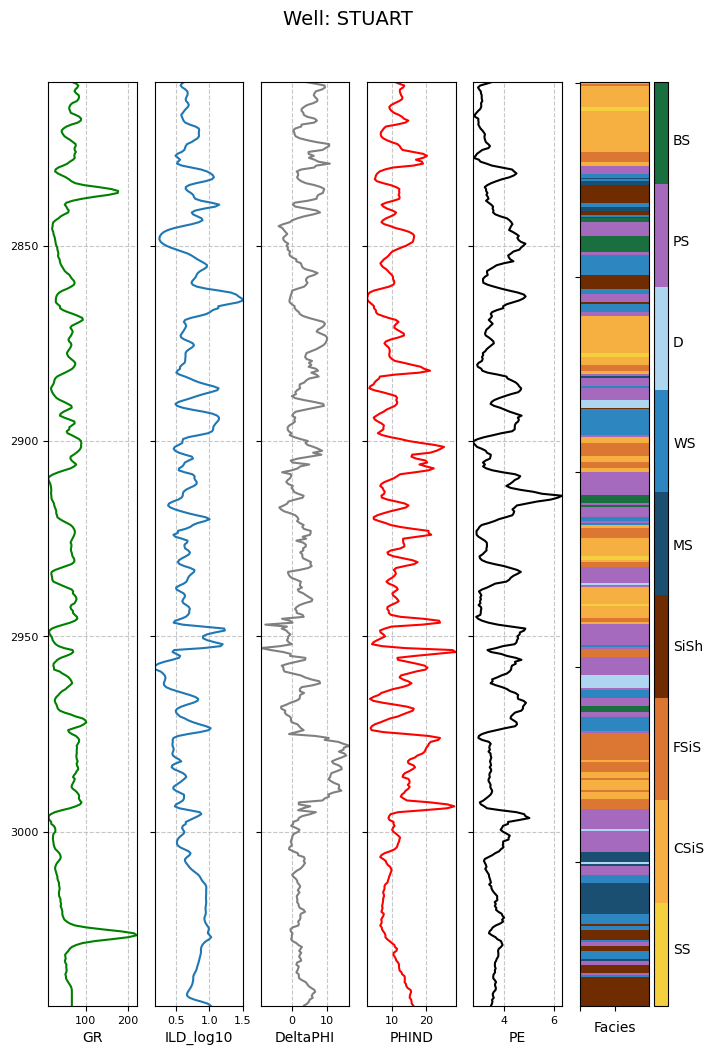


--- Visualizing Predicted Facies for CRAWFORD ---


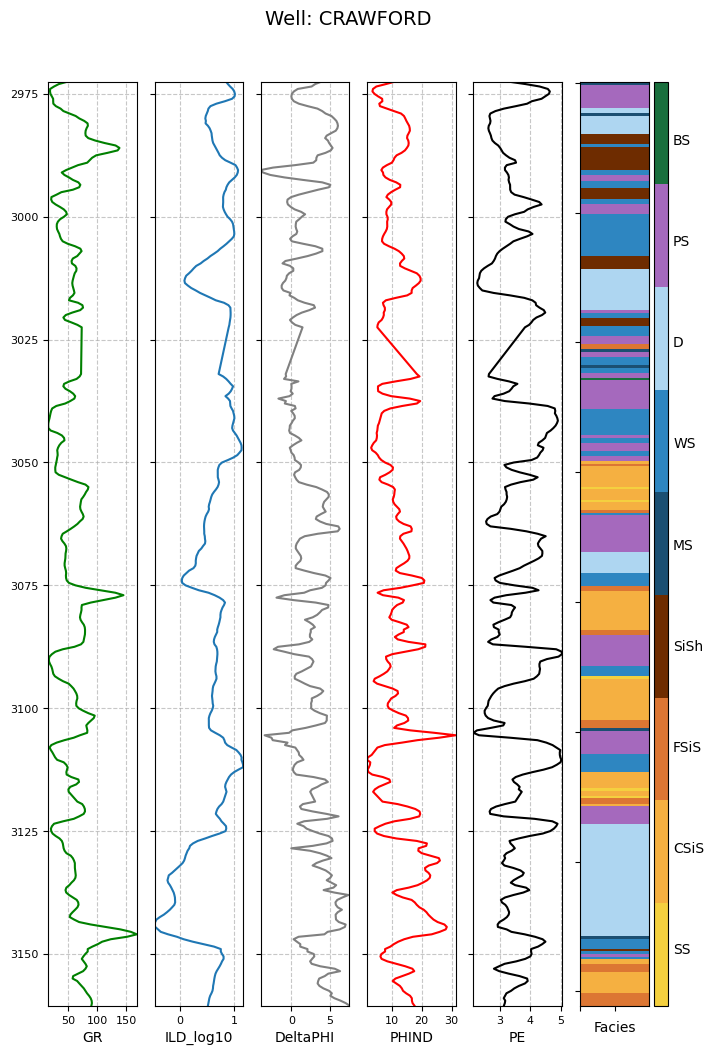

In [142]:
#Ploting the validation STUART Well.
print("\n--- Visualizing Predicted Facies for STUART ---")
make_facies_log_plot(
    well_data[well_data['Well Name'] == 'STUART'],
    facies_colors
)
plt.show()

#Ploting the validation CRAWFORD well
print("\n--- Visualizing Predicted Facies for CRAWFORD ---")
make_facies_log_plot(
    well_data[well_data['Well Name'] == 'CRAWFORD'],
    facies_colors
)
plt.show()

##### References
This dataset and the original problem framework are founded upon the following research papers:
* **Bohling, G. C., and M. K. Dubois (2003).** *An Integrated Application of Neural Network and Markov Chain Techniques to Prediction of Lithofacies from Well Logs*, KGS Open-File Report 2003-50, 6 pp.
* **Dubois, M. K., G. C. Bohling, and S. Chakrabarti (2007).** *Comparison of four approaches to a rock facies classification problem*, Computers & Geosciences, 33 (599-617).